# ENGS 27 Final Project: Storing Text in DNA

DNA is the densest storage medium known to humans. In principle, one gram of DNA can hold hundreds of
petabytes. Your job is to design a code that stores English text in strands of DNA, over the
four bases **A, C, G, T**, and recovers it after sequencing.

**The channel.** Strands are "synthesized", then sequenced. Each *read* is a random piece (substring) of one of your strands. You will need to study how these strands break up by sending in test strands and gathering statistics. Insights from your tests should help you design your proceedure!

**What you hand in.** A file `solution.py` defining two functions:

- `encode(text)`, which takes a string and returns a list of strands, each a string of
  `A`, `C`, `G` and `T`;
- `decode(reads)`, which takes a list of reads and returns the text.

You will also hand in a **one-page write-up** (one side, 12-point font) describing what you learned about the channel, how your design responds to it, and the evidence for both.

`decode` sees only the reads, so anything it needs, such as how long the text was, has to be stored in the strands that you send in from the encoder. For example, if you use a Huffman tree, you also need to send the tree in your message.

**How it is graded.** Your functions are run on three passages of English text, one short, one
medium and one long, which you will not see in advance. For each passage, your strands go through
the hidden channel, and `decode` receives a fixed total of **4 reads for every character of the
passage**. For example, you will get 4,000 reads for a 1,000-character passage. Each read is a random piece of
a randomly chosen strand, so some strands are read many times and others rarely, or not at all.
Each passage is scored by

$$\text{density} = \frac{8 \times \text{characters}}{\text{bases stored}}, \qquad
e = \frac{\text{edit distance}}{\text{characters}}, \qquad
\text{score} = \text{density} \times \bigl(1 - H(e)\bigr),$$

where $H$ is the binary entropy of Lecture 9, and your grade uses the average over the three passages. Density is bits of text per base, so
compression will be important. The *edit distance* counts the characters you would have to insert, delete or change to fix your output, so dropping one character costs one character (unlike Hamming distance, which would cost a lot in misalignment).

## Setup
Run this cell first. It connects to the course server; no class key is needed.

In [2]:
SERVER_URL = "https://dna.cedar.host.dartmouth.edu"
CLASS_KEY = ""

import random, collections, math
import requests
import numpy as np
import matplotlib.pyplot as plt

### Talking to the channel
`Channel().reads(strands, n)` sends your strands to the server and returns `n` reads. There is
no limit on how much you explore. `LocalChannel` does the same on your own computer, for
debugging, but **it is not the real channel**: its breaks happen independently with a fixed
probability. The real channel is more complicated.

In [4]:
class Channel:
    def __init__(self, url=SERVER_URL, key=CLASS_KEY):
        self.url, self.key = url.rstrip("/"), key
        self.max_per_request = requests.get(self.url + "/api/health", timeout=30).json()["limits"]["max_reads_per_request"]

    def reads(self, strands, n):
        got = []
        while len(got) < n:
            ask = min(n - len(got), self.max_per_request)
            r = requests.post(self.url + "/api/reads", timeout=300,
                              json={"key": self.key, "strands": list(strands), "n": ask})
            if r.status_code != 200:
                raise RuntimeError(r.json().get("error", r.text))
            got += r.json()["reads"]
        return got

class LocalChannel:
    def __init__(self, break_prob=0.03, min_read_length=8, seed=None):
        self.p, self.min_len, self.rng = break_prob, min_read_length, random.Random(seed)

    def _one(self, strands):
        while True:
            s = self.rng.choice(strands)
            cuts = [i for i in range(1, len(s)) if self.rng.random() < self.p]
            pieces = [s[a:b] for a, b in zip([0] + cuts, cuts + [len(s)])]
            pieces = [x for x in pieces if len(x) >= self.min_len]
            if pieces:
                return self.rng.choice(pieces)

    def reads(self, strands, n):
        return [self._one(list(strands)) for _ in range(n)]

## Part 1: Explore the channel

Send strands you know, read them back, and compare. Start with random strands, then design
strands that test a specific idea. Some questions that I recommend answering are:

1. What is the distribution of read lengths? Is it consistent with breaks happening
   independently at every position, which would make fragment lengths geometric?
2. Does the chance of a break depend on the bases around it? On how many of them?
3. How often does a read cover an entire strand of length $L$, as a function of $L$?

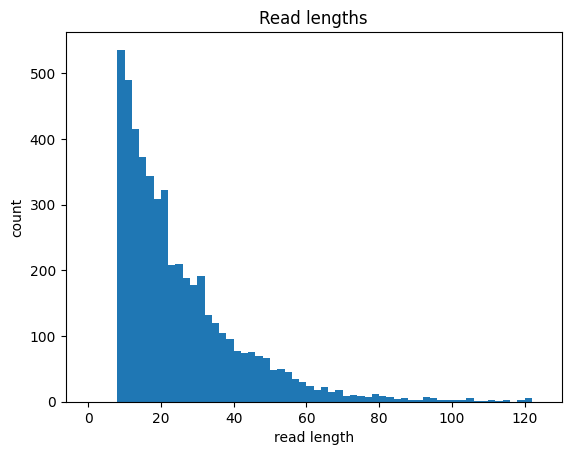

5000 reads, mean length 24.7


In [ ]:
channel = Channel()          # or LocalChannel() to practice offline

rng = random.Random(0)
test_strands = ["".join(rng.choice("ACGT") for _ in range(120)) for _ in range(100)]
test_reads = channel.reads(test_strands, 5000)

lengths = [len(r) for r in test_reads]
plt.hist(lengths, bins=range(0, 125, 2))
plt.xlabel("read length"); plt.ylabel("count"); plt.title("Read lengths")
plt.show()
print(f"{len(test_reads)} reads, mean length {np.mean(lengths):.1f}")

Because you know the strands you sent, you can find where each read came from, and so see
exactly where the molecule broke. This helper finds the strand and the starting position of
each read, whenever that is unambiguous.

In [ ]:
def locate(reads, strands):
    """For each read, find (strand index, start, length) if it occurs in exactly one strand."""
    out = []
    for r in reads:
        hits = [(j, s.find(r)) for j, s in enumerate(strands) if r in s]
        if len(hits) == 1:
            out.append((hits[0][0], hits[0][1], len(r)))
    return out

located = locate(test_reads, test_strands)
print(f"located {len(located)} of {len(test_reads)} reads")
j, start, n = located[0]
print(f"the first read is strand {j}, bases {start} to {start + n - 1}")

located 4369 of 5000 reads
the first read is strand 17, bases 65 to 112


## Part 2: A baseline solution

Here is a simple design that works, so you have something to beat. The text becomes bytes, and
the first four bytes record its length. Each strand is an **index**, six bases written in base
4, followed by a **payload** of four bytes at 2 bits per base. Strands are short, so that many
reads cover a whole strand. The decoder keeps only reads of exactly full length, reads each
one's index, and takes a majority vote per strand.

It wastes a lot: no compression, an index on every strand, partial reads thrown away, and
nothing protects a strand that is never read in full.

**This cell is your solution.** Running it saves `solution.py`, which is the file you hand in,
so keep everything your code needs inside it.

In [ ]:
%%writefile solution.py
import collections

INDEX, PAYLOAD = 6, 4          # bases of index, bytes of payload per strand
BASES = "ACGT"

def _to_bases(data):
    return "".join(BASES[(byte >> s) & 3] for byte in data for s in (6, 4, 2, 0))

def _to_bytes(bases):
    vals = [BASES.index(c) for c in bases]
    return bytes(vals[i] << 6 | vals[i + 1] << 4 | vals[i + 2] << 2 | vals[i + 3] for i in range(0, len(vals), 4))

def _index(i):
    return "".join(BASES[(i >> (2 * s)) & 3] for s in reversed(range(INDEX)))

def encode(text):
    data = text.encode("utf-8")
    data = len(data).to_bytes(4, "big") + data
    data += bytes(-len(data) % PAYLOAD)
    return [_index(i) + _to_bases(data[p:p + PAYLOAD])
            for i, p in enumerate(range(0, len(data), PAYLOAD))]

def decode(reads):
    full = INDEX + 4 * PAYLOAD
    votes = collections.defaultdict(collections.Counter)
    for r in reads:
        if len(r) == full:
            i = int("".join(str(BASES.index(c)) for c in r[:INDEX]), 4)
            votes[i][r[INDEX:]] += 1
    if not votes:
        return ""
    chunks = [_to_bytes(votes[i].most_common(1)[0][0]) if votes[i] else bytes(PAYLOAD)
              for i in range(max(votes) + 1)]
    data = b"".join(chunks)
    n = int.from_bytes(data[:4], "big")
    return data[4:4 + n].decode("utf-8", errors="replace")

Writing solution.py


## Part 3: Test it the way it will be graded

`evaluate` runs your `solution.py` exactly as the grader will: encode, 4 reads per character
through a channel, decode, and score. Try it on the local channel while you debug, and on the real channel before you hand in. The grading passages will be different from this one, so you may want to test on other passages to make sure your approach works well in general.

In [ ]:
import importlib, solution
importlib.reload(solution)

SAMPLE = """Every living cell carries its instructions written in a four-letter alphabet, and
it copies them with astonishing reliability. Engineers have begun to borrow the idea: a
library's worth of text, written into DNA and dried, could sit on a shelf for thousands of
years without power. The hard part is not the writing but the reading. A sequencer sees only
short fragments, in no particular order, and it is up to the code to put them back together."""

def edit_distance(a, b):
    if a == b: return 0
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb)))
        prev = cur
    return prev[-1]

def evaluate(text, channel, reads_per_char=4):
    strands = solution.encode(text)
    bases = sum(map(len, strands))
    decoded = solution.decode(channel.reads(strands, reads_per_char * len(text)))
    density = 8 * len(text.encode()) / bases
    e = min(1.0, edit_distance(decoded[:2 * len(text)], text) / len(text))
    info = 0.0 if e >= 0.5 else (1.0 if e == 0 else 1 + e * math.log2(e) + (1 - e) * math.log2(1 - e))
    print(f"{len(strands)} strands, {bases} bases: density {density:.3f}, "
          f"accuracy {1 - e:.4f}, SCORE {density * info:.4f}")
    return density * info

evaluate(SAMPLE, LocalChannel(seed=1))
evaluate(SAMPLE, Channel())


113 strands, 2486 bases: density 1.435, accuracy 1.0000, SCORE 1.4352
113 strands, 2486 bases: density 1.435, accuracy 0.9215, SCORE 0.8658


0.8657580824514548

## Doing better

There are many directions, and they combine:

- **Compress** (Lectures 9 and 10). English is far from random, so a code built for it, such as
  a Huffman code, stores the same text in fewer bits. Your decoder needs the code too.
- **Choose the strand length** (Lectures 7 and 23). Long strands waste fewer bases on indices,
  but are less likely to survive in one piece.
- **Assemble overlapping reads** (Lecture 15). Fragments that overlap can be stitched together,
  as in a de Bruijn graph, so strands need not be read whole.
- **Avoid repeats** (Problem Set 6). Substrings that repeat or overlap themselves make
  fragments hard to place.
- **Avoid what breaks** (Lecture 18). If some sequences break more often, a constrained code
  that never writes them keeps strands whole; counting the strings it allows tells you how many
  bits per base it can carry.
- **Add redundancy** (Lecture 11). Some strands may never be read well, some may be lost
  entirely, and reads may contain errors. Parity checks or other codes across strands can recover them for far less than
  storing everything twice.
- **Plan the coverage** (Lectures 6 and 7). With 4 reads per character, work out how many
  reads each strand gets, and how likely one is to be missed: a coupon collector problem.

**What to hand in:** `solution.py`, and the one-page write-up.